# KL 발산 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week15/kl_divergence/lab/kl_divergence.ipynb)

놀라움 $-\log_2 p$, 엔트로피 = 평균 놀라움, 교차 엔트로피 = 틀린 확률로 잰 평균 놀라움, KL = 그 차이.

- **파트 1**: 함수 만들기 → 뽑기 예시 0.24 · 0.40 · 0.16 비트
- **파트 2**: 뽑기 흉내 · 기록에 드는 비트
- **파트 3**: 봉우리 둘을 정규분포 하나로: 앞 방향 vs 뒤 방향 KL

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 파트 1. 네 가지 함수

공지 Q = (당첨 0.2, 꽝 0.8), 실제 P = (0.04, 0.96). 설명용 예시.

In [ ]:
def surprise(p):
    return -np.log2(p)

def entropy(p):
    p = np.asarray(p)
    return float(np.sum(p * surprise(p)))

def cross_entropy(p, q):
    p, q = np.asarray(p), np.asarray(q)
    return None  # TODO: surprise measured with q, averaged with p

def kl(p, q):
    p, q = np.asarray(p), np.asarray(q)
    return None  # TODO: KL(p || q) in bits

P, Q = [0.04, 0.96], [0.20, 0.80]
print("surprise of a win  (real / notice):", surprise(0.04).round(2), surprise(0.20).round(2))
print(f"H(P) = {entropy(P):.2f}   H(P,Q) = {cross_entropy(P, Q):.2f}   KL(P||Q) = {kl(P, Q):.2f}   KL(Q||P) = {kl(Q, P):.2f}")
print("classification, true (1, 0):", [round(cross_entropy([1, 1e-12], [q, 1 - q]), 2) for q in (0.7, 0.95, 0.5)])

**예상 결과**

```
surprise of a win  (real / notice): 4.64 2.32
H(P) = 0.24   H(P,Q) = 0.40   KL(P||Q) = 0.16   KL(Q||P) = 0.25
classification, true (1, 0): [0.51, 0.07, 1.0]
```

## 파트 2. 뽑기 흉내

In [ ]:
rng = np.random.default_rng(0)
draws = rng.geometric(0.04, 100_000)                     # draws until the first win, real 4%
draws_notice = rng.geometric(0.20, 100_000)
print(f"real 4%: mean {draws.mean():.1f}, median {np.median(draws):.0f}, more than 50 draws {np.mean(draws > 50):.0%}")
print(f"notice 20%: mean {draws_notice.mean():.1f}")
plt.hist(draws, bins=np.arange(1, 151, 3)); plt.axvline(5, color="orange", ls="--"); plt.axvline(draws.mean(), color="red", ls="--")
plt.xlabel("draws until the first win"); plt.show()

# Recording 1,000 results: average bits with a code built for P vs for Q
results = rng.random(1000) < 0.04                        # True = win
bits_real = sum(surprise(0.04) if r else surprise(0.96) for r in results)
bits_notice = sum(surprise(0.20) if r else surprise(0.80) for r in results)
print(f"bits for 1,000 records: real code {bits_real:.0f}, notice code {bits_notice:.0f}, wasted {bits_notice - bits_real:.0f}")

**예상 결과**

```
real 4%: mean 24.9, median 17, more than 50 draws 13%
notice 20%: mean 5.0
bits for 1,000 records: real code 293, notice code 424, wasted 131
```

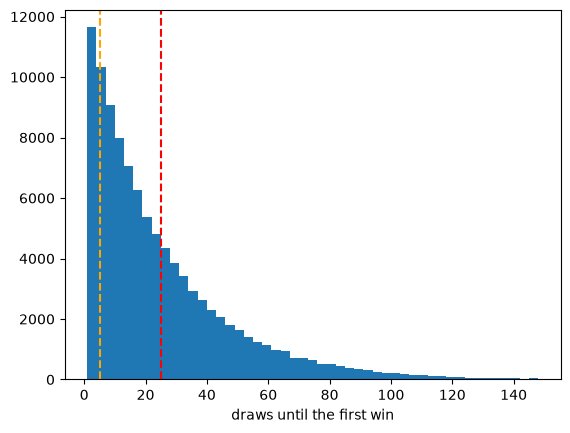

## 파트 3. 다 덮기 vs 하나 고르기

$P$: −2 와 +2 에 봉우리 (표준편차 0.5). 정규분포 $Q = N(m, s^2)$ 의 $m, s$ 를 격자로 찾는다.

In [ ]:
x = np.linspace(-8, 8, 4001); dx = x[1] - x[0]

def normal_pdf(x, m, s):
    return np.exp(-(x - m) ** 2 / (2 * s * s)) / (s * np.sqrt(2 * np.pi))

def kl_continuous(p, q, dx):
    p, q = p + 1e-300, q + 1e-300
    return float(np.sum(p * np.log(p / q)) * dx)         # natural log here

P_two = 0.5 * normal_pdf(x, -2, 0.5) + 0.5 * normal_pdf(x, 2, 0.5)
best = {"KL(P||Q)": (np.inf, None), "KL(Q||P)": (np.inf, None)}
for m in np.linspace(-3, 3, 121):
    for s in np.linspace(0.2, 3.5, 166):
        Qx = normal_pdf(x, m, s)
        for name, value in [("KL(P||Q)", kl_continuous(P_two, Qx, dx)), ("KL(Q||P)", kl_continuous(Qx, P_two, dx))]:
            if value < best[name][0]:
                best[name] = (value, (round(m, 2), round(s, 2)))
for name, (value, (m, s)) in best.items():
    print(f"min {name}: m = {m}, s = {s}, value {value:.3f}")
    plt.plot(x, normal_pdf(x, m, s), label=name)
plt.fill_between(x, P_two, alpha=0.3, label="P"); plt.xlim(-6, 6); plt.legend(); plt.show()

**예상 결과**

```
min KL(P||Q): m = 0.0, s = 2.06, value 0.724
min KL(Q||P): m = -2.0, s = 0.5, value 0.693
```

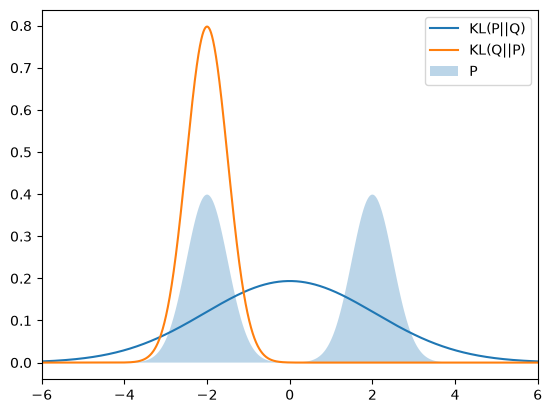

**확인 질문**
1. 파트 1 에서 KL(P‖Q) 와 KL(Q‖P) 가 다른 이유를 식으로 설명해 보라.
2. 파트 2 에서 낭비된 비트 수는 1,000 × KL 과 얼마나 비슷한가? 왜 정확히 같지는 않을까?
3. 파트 3 의 뒤 방향 최솟값 0.693 은 ln 2 와 같다. 왜 그럴까? (힌트: 봉우리 하나에만 붙으면 P 의 절반만 설명)
4. (도전) 실제 확률을 4% → 10% 로 바꾸면 KL(P‖Q) 는 어떻게 되나? 20% 면?